# Módulo 6 — A árvore binomial de Cox-Ross-Rubinstein

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** seção 5.4 e o Apêndice A.2.2 do livro.

## O que você vai conseguir fazer ao final

1. Calibrar uma árvore por casamento de momentos, e ver surgir o termo $-\tfrac12\sigma^2$.
2. Implementar a árvore de três formas e entender as diferenças de custo.
3. Mostrar que a árvore converge para a fórmula de BSM.
4. Explicar as oscilações do erro, e reduzi-las.
5. Extrair gregas da árvore sem reprecificar.
6. Precificar opções americanas e encontrar a fronteira de exercício.
7. Reconhecer a árvore como um método de diferenças finitas.

## Onde estamos

No Módulo 3, construímos árvores que **não recombinam**, com $2^M$ estados. Isso permite qualquer produto dependente da trajetória, mas fica inviável rapidamente. A árvore CRR faz $u \cdot d = 1$ para que os caminhos se reencontrem: são apenas $M+1$ nós na data final.

## 0. Preparação

In [1]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, binom
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def d12(S, K, tau, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * tau) / (sig * np.sqrt(tau))
    return d1, d1 - sig * np.sqrt(tau)


def bsm(S, K, tau, r, sig, tipo="call"):
    d1, d2 = d12(S, K, tau, r, sig)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)
    return K * np.exp(-r * tau) * norm.cdf(-d2) - S * norm.cdf(-d1)


S0, K0, T0, r0, s0 = 100.0, 100.0, 1.0, 0.05, 0.20
C_BSM = float(bsm(S0, K0, T0, r0, s0))
print("Ambiente pronto. Call BSM de referência:", f3(C_BSM))

Ambiente pronto. Call BSM de referência: 10,451


---
## 1. O modelo e sua calibração

**Livro: §5.4**

### 1.1 A estrutura

Dividimos $[0, T]$ em $M$ intervalos de $\Delta t = T/M$. Em cada passo, o índice é multiplicado por $u$ (alta) ou $d$ (queda). Sob $Q$, a probabilidade de alta é $q$. Como no Módulo 3, a condição de martingale do índice descontado fixa $q$:

$$q\,u + (1-q)\,d = e^{r\Delta t} \quad\Longrightarrow\quad q = \frac{e^{r\Delta t} - d}{u - d}.$$

### 1.2 Como escolher $u$ e $d$

Queremos que a árvore tenha, em cada passo, a volatilidade certa. CRR escolhe

$$u = e^{\sigma\sqrt{\Delta t}}, \qquad d = \frac{1}{u}.$$

Vejamos por que isso funciona, usando log-retornos. O log-retorno do passo vale $\pm a$, com $a = \sigma\sqrt{\Delta t}$.

**Variância do passo:**

$$\text{Var}^Q = (2a)^2\,q(1-q).$$

**Expansão de $q$.** Com Taylor, $u = 1 + a + \tfrac{a^2}{2} + \dots$, $d = 1 - a + \tfrac{a^2}{2} - \dots$ e $e^{r\Delta t} = 1 + r\Delta t + \dots$:

$$q = \frac{a + r\Delta t - \tfrac{a^2}{2} + \dots}{2a + \dots} = \frac12 + \frac{r\Delta t - \tfrac12\sigma^2\Delta t}{2\sigma\sqrt{\Delta t}} + \dots$$

**Consequências.** Com $q \to \tfrac12$, a variância tende a $4a^2\cdot\tfrac14 = \sigma^2\Delta t$. E a média do log-retorno é

$$(2q - 1)\,a = \frac{(r - \tfrac12\sigma^2)\Delta t}{\sigma\sqrt{\Delta t}}\cdot\sigma\sqrt{\Delta t} = \big(r - \tfrac12\sigma^2\big)\Delta t.$$

O termo $-\tfrac12\sigma^2$ reaparece **sem que ninguém o tenha colocado**: vem apenas da condição de martingale, a mesma lógica de Itô.

### 1.3 Condição de não arbitragem

Precisamos de $0 < q < 1$, ou seja, $d < e^{r\Delta t} < u$. Com $u = e^{\sigma\sqrt{\Delta t}}$, isso exige $|r|\sqrt{\Delta t} < \sigma$:

$$M > \frac{r^2 T}{\sigma^2}.$$

Em juros altos e volatilidade baixa, uma árvore grosseira pode ter arbitragem, e essa condição não é detalhe: num cenário de 13% ao ano com volatilidade de 5%, são necessários mais de 6 passos para cada ano.

### Laboratório 1.1 — Reproduzindo a Tabela 5.1 do livro

In [2]:
def params_crr(T, r, sig, M):
    dt = T / M
    u = np.exp(sig * np.sqrt(dt))
    d = 1 / u
    q = (np.exp(r * dt) - d) / (u - d)
    return dt, u, d, q


def arvore_completa(S0, K, T, r, sig, M):
    """Devolve as matrizes de índice e de valor, para inspeção de árvores pequenas."""
    dt, u, d, q = params_crr(T, r, sig, M)
    S = np.full((M + 1, M + 1), np.nan)
    V = np.full((M + 1, M + 1), np.nan)
    for t in range(M + 1):
        for j in range(t + 1):
            S[j, t] = S0 * u ** (t - j) * d**j
    V[:, M] = np.maximum(S[:, M] - K, 0)
    desc = np.exp(-r * dt)
    for t in range(M - 1, -1, -1):
        for j in range(t + 1):
            V[j, t] = desc * (q * V[j, t + 1] + (1 - q) * V[j + 1, t + 1])
    return S, V, q


Sa, Va, q4 = arvore_completa(S0, K0, T0, r0, s0, 4)
rot = ["t=0", "Δt", "2Δt", "3Δt", "T"]
print("Índice:")
tabela(pd.DataFrame(Sa, columns=rot))
print("Call:")
tabela(pd.DataFrame(Va, columns=rot))
print("q =", f3(float(q4)))

ok(abs(q4 - 0.5378) < 5e-4, "q coincide com o livro")
ok(abs(Va[0, 0] - 9.97) < 0.005 and abs(Va[0, 3] - 36.23) < 0.005 and abs(Sa[0, 4] - 149.18) < 0.005, "valores coincidem com a Tabela 5.1")

linhas = []
for M in [4, 16, 64, 256, 1024]:
    dt, u, d, q = params_crr(T0, r0, s0, M)
    a = s0 * np.sqrt(dt)
    linhas.append({"M": M, "q": float(q), "Média do log-passo (×M)": float((2 * q - 1) * a * M), "Teoria (r−σ²/2)T": (r0 - 0.5 * s0**2) * T0, "Variância do log-passo (×M)": float(4 * a**2 * q * (1 - q) * M), "Teoria σ²T": s0**2 * T0})
mom = pd.DataFrame(linhas)
tabela(mom)
ok(abs(mom["Média do log-passo (×M)"].iloc[-1] - mom["Teoria (r−σ²/2)T"].iloc[-1]) < 1e-3, "o drift converge para r − σ²/2")
ok(abs(mom["Variância do log-passo (×M)"].iloc[-1] - s0**2 * T0) < 1e-3, "a variância converge para σ²T")

_, _, _, q_mau = params_crr(1.0, 0.13, 0.05, 4)
_, _, _, q_bom = params_crr(1.0, 0.13, 0.05, 12)
print("r=13%, σ=5%: q com M=4:", f3(float(q_mau)), "| com M=12:", f3(float(q_bom)))
ok(q_mau > 1 and 0 < q_bom < 1, "árvores grosseiras podem violar a condição de não arbitragem")

Índice:


,t=0,Δt,2Δt,3Δt,T
0,"100,000","110,517","122,140","134,986","149,182"
1,n/d,"90,484","100,000","110,517","122,140"
2,n/d,n/d,"81,873","90,484","100,000"
3,n/d,n/d,n/d,"74,082","81,873"
4,n/d,n/d,n/d,n/d,"67,032"


Call:


,t=0,Δt,2Δt,3Δt,T
0,"9,971","15,922","24,609","36,228","49,182"
1,n/d,"3,317","6,246","11,759","22,140"
2,n/d,n/d,"0,000","0,000","0,000"
3,n/d,n/d,n/d,"0,000","0,000"
4,n/d,n/d,n/d,n/d,"0,000"


q = 0,538
OK — q coincide com o livro
OK — valores coincidem com a Tabela 5.1


,M,q,Média do log-passo (×M),Teoria (r−σ²/2)T,Variância do log-passo (×M),Teoria σ²T
0,4,"0,538","0,030","0,030","0,040","0,040"
1,16,"0,519","0,030","0,030","0,040","0,040"
2,64,"0,509","0,030","0,030","0,040","0,040"
3,256,"0,505","0,030","0,030","0,040","0,040"
4,1024,"0,502","0,030","0,030","0,040","0,040"


OK — o drift converge para r − σ²/2
OK — a variância converge para σ²T
r=13%, σ=5%: q com M=4: 1,154 | com M=12: 0,874
OK — árvores grosseiras podem violar a condição de não arbitragem


> **Errata do livro:** a nota da Tabela 5.1 diz "the true value of the European **put** option is 10.45". A tabela é da **call**; a put vale 5,574.

---
## 2. Três implementações

**Livro: Apêndice A.2.2**

Há três formas equivalentes de obter o mesmo número, com custos bem diferentes.

**A. Laços duplos.** A forma literal do algoritmo. Custo de $M^2/2$ operações em Python puro.

**B. Vetorizada.** A cada passo para trás, uma única operação sobre o vetor de valores:

$$V^{t} = e^{-r\Delta t}\big[q\,V^{t+1}_{1:} + (1-q)\,V^{t+1}_{:-1}\big].$$

Mesmo custo teórico, mas em C. Só é preciso guardar a última coluna: memória $O(M)$.

**C. Soma binomial fechada.** Para payoffs que só dependem de $S_T$, a árvore tem solução direta. O nó com $j$ altas tem probabilidade binomial:

$$C_0 = e^{-rT}\sum_{j=0}^{M}\binom{M}{j}q^j(1-q)^{M-j}\max\big(S_0u^jd^{M-j} - K, 0\big).$$

Custo $O(M)$. Não serve para americanas, nem para produtos dependentes da trajetória.

### 2.1 Fechando a conta

Seja $a$ o menor $j$ com $S_0u^jd^{M-j} > K$. Separando o payoff em dois termos, como no Módulo 5:

$$C_0 = S_0\,\mathcal{B}(a; M, q') - Ke^{-rT}\mathcal{B}(a; M, q), \qquad q' = q\,u\,e^{-r\Delta t},$$

em que $\mathcal{B}$ é a cauda superior da binomial. $q'$ é a probabilidade de alta **sob a medida em que o índice é o numerário**, assim como $N(d_1)$. Pelo teorema central do limite, $\mathcal{B}(a; M, q) \to N(d_2)$ e $\mathcal{B}(a; M, q') \to N(d_1)$. Logo, a árvore tende à fórmula de BSM.

### Laboratório 2.1 — Corrida de implementações

In [3]:
def crr_laco(S0, K, T, r, sig, M):
    dt, u, d, q = params_crr(T, r, sig, M)
    desc = np.exp(-r * dt)
    V = [max(S0 * u**j * d ** (M - j) - K, 0.0) for j in range(M + 1)]
    for t in range(M - 1, -1, -1):
        for j in range(t + 1):
            V[j] = desc * (q * V[j + 1] + (1 - q) * V[j])
    return V[0]


def crr_vetor(S0, K, T, r, sig, M):
    dt, u, d, q = params_crr(T, r, sig, M)
    desc = np.exp(-r * dt)
    j = np.arange(M + 1)
    V = np.maximum(S0 * u**j * d ** (M - j) - K, 0.0)
    for _ in range(M):
        V = desc * (q * V[1:] + (1 - q) * V[:-1])
    return float(V[0])


def crr_fechada(S0, K, T, r, sig, M):
    dt, u, d, q = params_crr(T, r, sig, M)
    a = int(np.floor(np.log(K / (S0 * d**M)) / np.log(u / d))) + 1
    a = min(max(a, 0), M + 1)
    q_ = q * u * np.exp(-r * dt)
    return float(S0 * binom.sf(a - 1, M, q_) - K * np.exp(-r * T) * binom.sf(a - 1, M, q))


linhas = []
for M in [100, 500, 2000]:
    regs = {}
    for nome, f in [("Laços", crr_laco), ("Vetorizada", crr_vetor), ("Fechada", crr_fechada)]:
        t0 = perf_counter()
        v = f(S0, K0, T0, r0, s0, M)
        regs[nome] = (v, (perf_counter() - t0) * 1000)
    linhas.append({"M": M, "Valor": regs["Fechada"][0], "Laços (ms)": regs["Laços"][1], "Vetorizada (ms)": regs["Vetorizada"][1], "Fechada (ms)": regs["Fechada"][1]})
    ok(abs(regs["Laços"][0] - regs["Vetorizada"][0]) < 1e-9 and abs(regs["Fechada"][0] - regs["Vetorizada"][0]) < 1e-8, f"as três implementações coincidem para M = {M}")
corrida = pd.DataFrame(linhas)
tabela(corrida)
ok(corrida["Vetorizada (ms)"].iloc[-1] < corrida["Laços (ms)"].iloc[-1], "a vetorização é mais rápida que os laços")

d1, d2 = d12(S0, K0, T0, r0, s0)
linhas = []
for M in [10, 100, 1000, 10000]:
    dt, u, d, q = params_crr(T0, r0, s0, M)
    a = int(np.floor(np.log(K0 / (S0 * d**M)) / np.log(u / d))) + 1
    linhas.append({"M": M, "Cauda sob q": float(binom.sf(a - 1, M, q)), "N(d2)": float(norm.cdf(d2)), "Cauda sob q'": float(binom.sf(a - 1, M, q * u * np.exp(-r0 * dt))), "N(d1)": float(norm.cdf(d1))})
cau = pd.DataFrame(linhas)
tabela(cau)
ok(abs(cau["Cauda sob q"].iloc[-1] - norm.cdf(d2)) < 0.005 and abs(cau["Cauda sob q'"].iloc[-1] - norm.cdf(d1)) < 0.005, "as caudas binomiais convergem para N(d2) e N(d1)")

OK — as três implementações coincidem para M = 100
OK — as três implementações coincidem para M = 500


OK — as três implementações coincidem para M = 2000


,M,Valor,Laços (ms),Vetorizada (ms),Fechada (ms)
0,100,"10,431","1,233","0,368","0,307"
1,500,"10,447","24,746","1,246","0,218"
2,2000,"10,450","419,164","6,405","0,280"


OK — a vetorização é mais rápida que os laços


,M,Cauda sob q,N(d2),Cauda sob q',N(d1)
0,10,"0,437","0,560","0,518","0,637"
1,100,"0,599","0,560","0,674","0,637"
2,1000,"0,547","0,560","0,625","0,637"
3,10000,"0,564","0,560","0,641","0,637"


OK — as caudas binomiais convergem para N(d2) e N(d1)


---
## 3. Convergência e seus padrões

**Livro: §5.4 e Figuras 5.8 e 5.9**

### 3.1 Por que o erro oscila

O valor da árvore é uma soma sobre nós. Se $K$ cair sobre um nó ou entre dois, o resultado muda. Variar $M$ desloca os nós em relação a $K$, e o erro oscila.

- Com $K = S_0$, um nó central só existe se $M$ for **par**. Com $M$ ímpar, $K$ cai no meio de dois nós.
- É isso que aparece nas figuras do livro: usando passos de 20 em 20, todo $M$ é par e o valor parece vir por baixo. Com passos de 25 em 25, $M$ alterna entre par e ímpar e o valor oscila.

> **Sobre o texto do livro.** Ele atribui a oscilação a uma "parametrização numérica diferente". Não há outra parametrização: é o mesmo modelo, e a diferença é apenas a paridade de $M$ em relação à posição do strike.

Para $K$ fora do dinheiro, o padrão é mais complicado, com um **dente de serra** irregular.

### 3.2 Três melhorias

**Média de dois vizinhos.** Com $M$ e $M+1$, os erros têm sinais opostos no ATM, e a média cancela boa parte.

**Suavização e Richardson (BBSR).** O payoff tem quina, e é ela que causa as oscilações. Broadie e Detemple propõem trocar o último passo pelo valor BSM em $\Delta t$. A quina desaparece e o erro fica liso, o que permite a extrapolação de Richardson. Se o erro é $c/M$:

$$V_M = V + \frac{c}{M}, \quad V_{M/2} = V + \frac{2c}{M} \quad\Longrightarrow\quad V = 2V_M - V_{M/2}.$$

**Leisen-Reimer.** Em vez de casar momentos, escolhe-se $q$ e $q'$ de modo que as caudas binomiais aproximem $N(d_2)$ e $N(d_1)$ diretamente, pela inversão de Peizer-Pratt, com $M$ ímpar:

$$h(z) = \frac12 + \frac{\text{sinal}(z)}{2}\sqrt{1 - \exp\Big[-\Big(\frac{z}{M + \tfrac13 + \tfrac{0{,}1}{M+1}}\Big)^2\big(M + \tfrac16\big)\Big]},$$

com $q = h(d_2)$, $q' = h(d_1)$, $u = e^{r\Delta t}q'/q$ e $d = (e^{r\Delta t} - qu)/(1 - q)$.

### Laboratório 3.1 — O padrão do erro

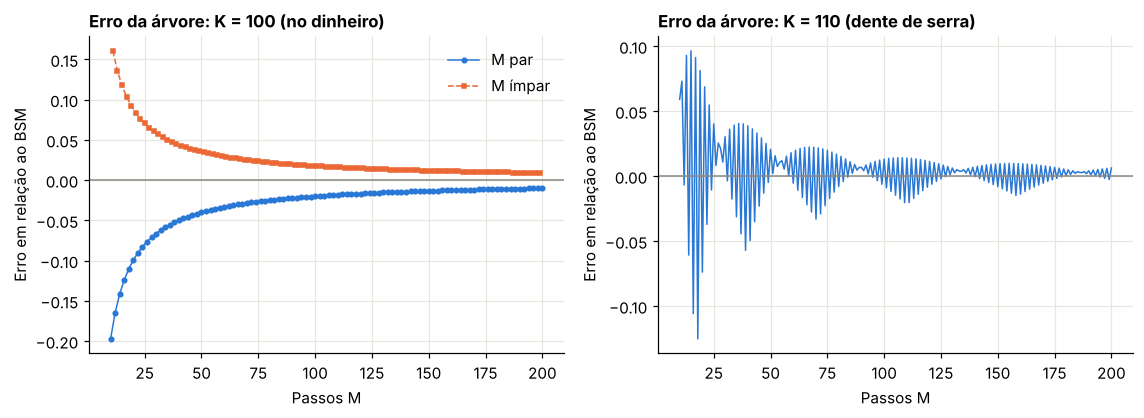

OK — com M par e K no dinheiro, a árvore fica abaixo do BSM
OK — com M ímpar e K no dinheiro, a árvore fica acima do BSM
Trocas de sinal do erro para K = 110: 140
OK — fora do dinheiro, o erro troca de sinal irregularmente


In [4]:
Ms = np.arange(10, 201)
err_atm = np.array([crr_fechada(S0, 100.0, T0, r0, s0, int(M)) for M in Ms]) - float(bsm(S0, 100.0, T0, r0, s0))
err_otm = np.array([crr_fechada(S0, 110.0, T0, r0, s0, int(M)) for M in Ms]) - float(bsm(S0, 110.0, T0, r0, s0))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
a1.plot(Ms[Ms % 2 == 0], err_atm[Ms % 2 == 0], color=AZUL, marker="o", markersize=3, lw=1, label="M par")
a1.plot(Ms[Ms % 2 == 1], err_atm[Ms % 2 == 1], color=LARANJA, marker="s", markersize=3, lw=1, ls="--", label="M ímpar")
a1.axhline(0, color=CINZA, lw=1)
a1.set_title("Erro da árvore: K = 100 (no dinheiro)")
a1.set_xlabel("Passos M")
a1.set_ylabel("Erro em relação ao BSM")
a1.legend()
a2.plot(Ms, err_otm, color=AZUL, lw=1)
a2.axhline(0, color=CINZA, lw=1)
a2.set_title("Erro da árvore: K = 110 (dente de serra)")
a2.set_xlabel("Passos M")
a2.set_ylabel("Erro em relação ao BSM")
plt.tight_layout()
plt.show()

ok(np.all(err_atm[Ms % 2 == 0] < 0), "com M par e K no dinheiro, a árvore fica abaixo do BSM")
ok(np.all(err_atm[Ms % 2 == 1] > 0), "com M ímpar e K no dinheiro, a árvore fica acima do BSM")
trocas = int(np.sum(np.diff(np.sign(err_otm)) != 0))
print("Trocas de sinal do erro para K = 110:", trocas)
ok(trocas > 5, "fora do dinheiro, o erro troca de sinal irregularmente")

### Laboratório 3.2 — Comparando os métodos

Erro absoluto médio em 3 strikes (×1000):


Método,M,CRR,Média M e M+1,BBSR,Leisen-Reimer
0,50,"22,036","8,053","0,837","0,089"
1,100,"14,439","3,888","0,084","0,023"
2,200,"7,380","1,628","0,093","0,006"
3,400,"4,165","1,038","0,008","0,001"
4,800,"1,745","0,121","0,009","0,000"
5,1600,"1,130","0,146","0,002","0,000"


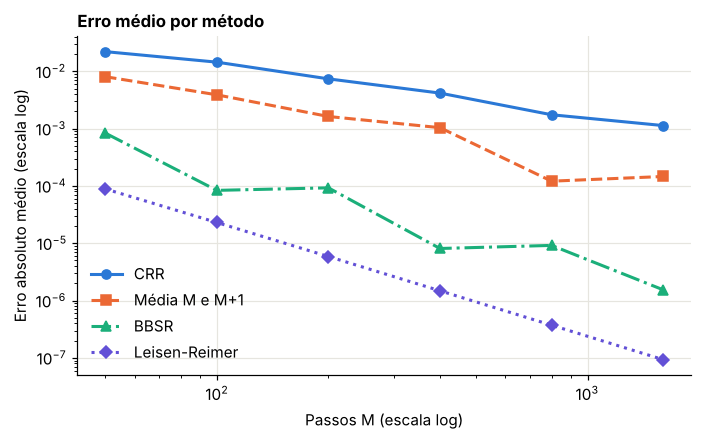

OK — Leisen-Reimer reduz o erro em pelo menos duas ordens de grandeza
OK — BBSR reduz bastante o erro


In [5]:
def recursao(V, u, d, q, dt, r, M):
    desc = np.exp(-r * dt)
    for _ in range(M):
        V = desc * (q * V[1:] + (1 - q) * V[:-1])
    return float(V[0])


def bbs(S0, K, T, r, sig, M):
    """Árvore com o último passo substituído pelo valor BSM."""
    dt, u, d, q = params_crr(T, r, sig, M)
    j = np.arange(M)
    S = S0 * u**j * d ** (M - 1 - j)
    return recursao(bsm(S, K, dt, r, sig), u, d, q, dt, r, M - 1)


def bbsr(S0, K, T, r, sig, M):
    return 2 * bbs(S0, K, T, r, sig, M) - bbs(S0, K, T, r, sig, M // 2)


def leisen_reimer(S0, K, T, r, sig, M):
    M = M + 1 if M % 2 == 0 else M
    dt = T / M
    d1, d2 = d12(S0, K, T, r, sig)

    def h(z):
        return 0.5 + np.sign(z) * 0.5 * np.sqrt(1 - np.exp(-((z / (M + 1 / 3 + 0.1 / (M + 1))) ** 2) * (M + 1 / 6)))

    q, q_ = h(d2), h(d1)
    u = np.exp(r * dt) * q_ / q
    d = (np.exp(r * dt) - q * u) / (1 - q)
    j = np.arange(M + 1)
    return recursao(np.maximum(S0 * u**j * d ** (M - j) - K, 0.0), u, d, q, dt, r, M)


def media_viz(S0, K, T, r, sig, M):
    return 0.5 * (crr_fechada(S0, K, T, r, sig, M) + crr_fechada(S0, K, T, r, sig, M + 1))


metodos = {"CRR": crr_fechada, "Média M e M+1": media_viz, "BBSR": bbsr, "Leisen-Reimer": leisen_reimer}
linhas = []
grade_M = [50, 100, 200, 400, 800, 1600]
for K_ in [90.0, 100.0, 115.0]:
    ref = float(bsm(S0, K_, T0, r0, s0))
    for nome, f in metodos.items():
        for M in grade_M:
            linhas.append({"Strike": K_, "Método": nome, "M": M, "Erro": abs(f(S0, K_, T0, r0, s0, M) - ref)})
er = pd.DataFrame(linhas)
media_err = er.groupby(["Método", "M"])["Erro"].mean().unstack(0)[list(metodos)]
print("Erro absoluto médio em 3 strikes (×1000):")
tabela((media_err * 1000).reset_index())

fig, ax = plt.subplots()
for (nome, cor, est, mark) in [("CRR", AZUL, "-", "o"), ("Média M e M+1", LARANJA, "--", "s"), ("BBSR", VERDE, "-.", "^"), ("Leisen-Reimer", "#6250d6", ":", "D")]:
    ax.loglog(media_err.index, media_err[nome], color=cor, ls=est, marker=mark, markersize=6, label=nome)
ax.set_title("Erro médio por método")
ax.set_xlabel("Passos M (escala log)")
ax.set_ylabel("Erro absoluto médio (escala log)")
ax.legend()
plt.show()

ultimo = media_err.iloc[-1]
ok(ultimo["Leisen-Reimer"] < ultimo["CRR"] / 100, "Leisen-Reimer reduz o erro em pelo menos duas ordens de grandeza")
ok(ultimo["BBSR"] < ultimo["CRR"] / 20, "BBSR reduz bastante o erro")

---
## 4. Gregas a partir da árvore

Uma das vantagens da árvore: os nós das primeiras datas já contêm a informação das sensibilidades, sem reprecificar.

**Delta**, com os dois nós de $\Delta t$:

$$\Delta \approx \frac{V_u - V_d}{S_0(u - d)}.$$

**Gama**, com os três nós de $2\Delta t$, como variação do delta:

$$\Gamma \approx \frac{\dfrac{V_{uu} - V_{ud}}{S_{uu} - S_{ud}} - \dfrac{V_{ud} - V_{dd}}{S_{ud} - S_{dd}}}{\tfrac12(S_{uu} - S_{dd})}.$$

**Teta**: como $ud = 1$, o nó central de $2\Delta t$ tem o mesmo índice que a raiz:

$$\Theta \approx \frac{V_{ud} - V_0}{2\Delta t}.$$

### Laboratório 4.1 — Gregas da árvore

In [6]:
def arvore_gregas(S0, K, T, r, sig, M, tipo="call", americana=False):
    """Árvore vetorizada que devolve o valor, as gregas e a fronteira de exercício (para put)."""
    dt, u, d, q = params_crr(T, r, sig, M)
    desc = np.exp(-r * dt)
    sinal = 1.0 if tipo == "call" else -1.0
    j = np.arange(M + 1)
    V = np.maximum(sinal * (S0 * u**j * d ** (M - j) - K), 0.0)
    guardados, fronteira = {}, np.full(M + 1, np.nan)
    fronteira[M] = K
    for t in range(M - 1, -1, -1):
        V = desc * (q * V[1:] + (1 - q) * V[:-1])
        if americana:
            j = np.arange(t + 1)
            St = S0 * u**j * d ** (t - j)
            intr = np.maximum(sinal * (St - K), 0.0)
            exerce = intr > V + 1e-12
            V = np.where(exerce, intr, V)
            if tipo == "put" and exerce.any():
                fronteira[t] = St[exerce].max()
        if t <= 2:
            guardados[t] = V.copy()
    V0 = float(guardados[0][0])
    Vd, Vu = guardados[1]
    Vdd, Vud, Vuu = guardados[2]
    delta = (Vu - Vd) / (S0 * (u - d))
    Suu, Sud, Sdd = S0 * u**2, S0, S0 * d**2
    gama = ((Vuu - Vud) / (Suu - Sud) - (Vud - Vdd) / (Sud - Sdd)) / (0.5 * (Suu - Sdd))
    teta = (Vud - V0) / (2 * dt)
    return {"valor": V0, "delta": delta, "gama": gama, "teta": teta, "fronteira": fronteira}


g = arvore_gregas(S0, K0, T0, r0, s0, 2000)
d1, d2 = d12(S0, K0, T0, r0, s0)
exato = {
    "delta": float(norm.cdf(d1)),
    "gama": float(norm.pdf(d1) / (S0 * s0 * np.sqrt(T0))),
    "teta": float(-S0 * norm.pdf(d1) * s0 / (2 * np.sqrt(T0)) - r0 * K0 * np.exp(-r0 * T0) * norm.cdf(d2)),
}
tabela(pd.DataFrame([{"Grega": k, "Árvore (M=2000)": float(g[k]), "BSM": v} for k, v in exato.items()]))
ok(abs(g["delta"] - exato["delta"]) < 2e-3, "delta da árvore")
ok(abs(g["gama"] - exato["gama"]) < 1e-3, "gama da árvore")
ok(abs(g["teta"] - exato["teta"]) < 0.02, "teta da árvore")

,Grega,Árvore (M=2000),BSM
0,delta,"0,637","0,637"
1,gama,"0,019","0,019"
2,teta,"-6,416","-6,414"


OK — delta da árvore
OK — gama da árvore
OK — teta da árvore


---
## 5. Opções americanas

**Livro: §5.4; o Módulo 9 aprofunda com simulação**

Agora vem a principal vantagem prática. Em cada nó, o titular de uma opção americana escolhe o melhor entre exercer e continuar:

$$V_{\text{nó}} = \max\big(\underbrace{h(S_{\text{nó}})}_{\text{exercer}},\ \underbrace{e^{-r\Delta t}\big[qV_{\text{sobe}} + (1-q)V_{\text{desce}}\big]}_{\text{continuar}}\big).$$

É a **programação dinâmica**. Bastou acrescentar um `max` à recursão.

### 5.1 Call americana sem dividendos

Do Módulo 1: uma call europeia vale pelo menos $S - Ke^{-r\tau}$. Com $r > 0$, isso é maior que o valor de exercício $S - K$. Logo, **nunca compensa exercer antes**: vivo vale mais que morto. Portanto, call americana sem dividendos é igual à europeia.

### 5.2 Put americana

Para a put o argumento se inverte. Se a put estiver muito dentro do dinheiro, o titular prefere receber $K$ já e aplicar. Existe uma **fronteira de exercício** $S^*(t)$: abaixo dela, o exercício é ótimo. Com $r = 0$, não há esse incentivo, e a put americana é igual à europeia.

### Laboratório 5.1 — Put americana

Usamos os parâmetros do exemplo clássico de Longstaff e Schwartz: $S_0 = 36$, $K = 40$, $T = 1$, $r = 6\%$, $\sigma = 20\%$.

,M,Americana,Europeia,Prêmio de exercício
0,50,"4,484","3,840","0,645"
1,100,"4,488","3,848","0,640"
2,500,"4,486","3,844","0,643"
3,1000,"4,487","3,845","0,642"
4,2000,"4,487","3,844","0,642"
5,4000,"4,487","3,844","0,642"


BSM europeia: 3,844
OK — o valor americano converge
OK — a put americana vale mais que a europeia
OK — call americana sem dividendos é igual à europeia
OK — com juros zero, a put americana é igual à europeia


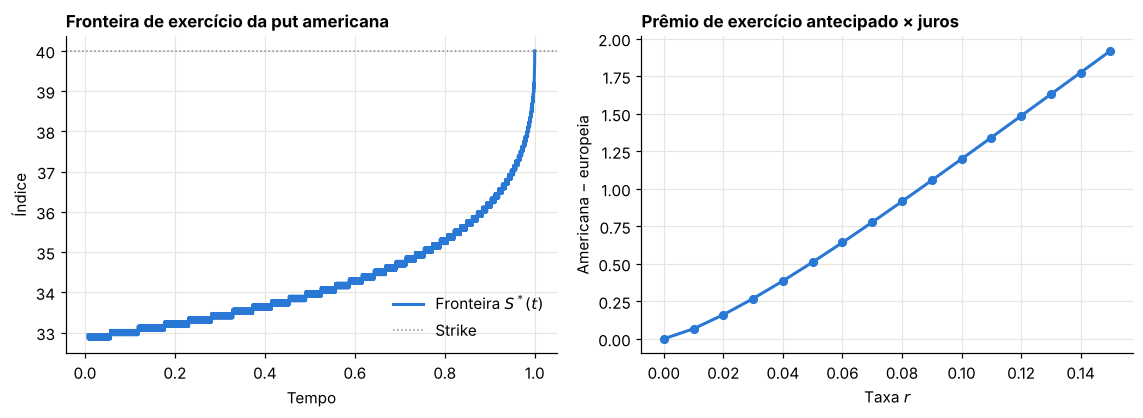

OK — a fronteira sobe com o tempo e termina perto do strike
OK — o prêmio de exercício cresce com os juros


In [7]:
S_a, K_a, T_a, r_a, s_a = 36.0, 40.0, 1.0, 0.06, 0.20
linhas = []
for M in [50, 100, 500, 1000, 2000, 4000]:
    am = arvore_gregas(S_a, K_a, T_a, r_a, s_a, M, "put", True)["valor"]
    eu = arvore_gregas(S_a, K_a, T_a, r_a, s_a, M, "put", False)["valor"]
    linhas.append({"M": M, "Americana": am, "Europeia": eu, "Prêmio de exercício": am - eu})
tb = pd.DataFrame(linhas)
tabela(tb)
print("BSM europeia:", f3(float(bsm(S_a, K_a, T_a, r_a, s_a, "put"))))

ok(abs(tb["Americana"].iloc[-1] - tb["Americana"].iloc[-2]) < 1e-3, "o valor americano converge")
ok((tb["Americana"] > tb["Europeia"]).all(), "a put americana vale mais que a europeia")

call_am = arvore_gregas(100.0, 100.0, 1.0, 0.05, 0.2, 500, "call", True)["valor"]
call_eu = arvore_gregas(100.0, 100.0, 1.0, 0.05, 0.2, 500, "call", False)["valor"]
ok(abs(call_am - call_eu) < 1e-9, "call americana sem dividendos é igual à europeia")
p_am0 = arvore_gregas(S_a, K_a, T_a, 0.0, s_a, 500, "put", True)["valor"]
p_eu0 = arvore_gregas(S_a, K_a, T_a, 0.0, s_a, 500, "put", False)["valor"]
ok(abs(p_am0 - p_eu0) < 1e-9, "com juros zero, a put americana é igual à europeia")

M_f = 4000
res_f = arvore_gregas(S_a, K_a, T_a, r_a, s_a, M_f, "put", True)
ts = np.arange(M_f + 1) * T_a / M_f
fr = pd.Series(res_f["fronteira"]).ffill().values

premio = []
grade_r = np.linspace(0.0, 0.15, 16)
for r_ in grade_r:
    premio.append(arvore_gregas(S_a, K_a, T_a, float(r_), s_a, 800, "put", True)["valor"] - arvore_gregas(S_a, K_a, T_a, float(r_), s_a, 800, "put", False)["valor"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
a1.plot(ts[5:], fr[5:], color=AZUL, label="Fronteira $S^*(t)$")
a1.axhline(K_a, color=CINZA, lw=1, ls=":", label="Strike")
a1.set_title("Fronteira de exercício da put americana")
a1.set_xlabel("Tempo")
a1.set_ylabel("Índice")
a1.legend()
a2.plot(grade_r, premio, color=AZUL, marker="o", markersize=5)
a2.set_title("Prêmio de exercício antecipado × juros")
a2.set_xlabel("Taxa $r$")
a2.set_ylabel("Americana − europeia")
plt.tight_layout()
plt.show()

ok(fr[int(0.9 * M_f)] > fr[int(0.1 * M_f)] and fr[-2] < K_a + 1e-9, "a fronteira sobe com o tempo e termina perto do strike")
ok(np.all(np.diff(premio) > 0), "o prêmio de exercício cresce com os juros")

### Laboratório 5.2 — Exercício apenas em algumas datas (bermudana)

Uma opção **bermudana** só pode ser exercida em datas específicas. É o que um algoritmo de simulação como o do Módulo 9 realmente precifica, com um número finito de datas de exercício. Vale a pena ter uma noção do efeito.

In [8]:
def bermudana(S0, K, T, r, sig, M, datas):
    """Put que só pode ser exercida em 'datas' datas igualmente espaçadas."""
    dt, u, d, q = params_crr(T, r, sig, M)
    desc = np.exp(-r * dt)
    j = np.arange(M + 1)
    V = np.maximum(K - S0 * u**j * d ** (M - j), 0.0)
    passo = M // datas
    for t in range(M - 1, -1, -1):
        V = desc * (q * V[1:] + (1 - q) * V[:-1])
        if t % passo == 0 and t > 0:
            j = np.arange(t + 1)
            V = np.maximum(V, K - S0 * u**j * d ** (t - j))
    return float(V[0])


M_b = 4800
linhas = [{"Datas de exercício": n, "Valor": bermudana(S_a, K_a, T_a, r_a, s_a, M_b, n)} for n in [1, 2, 4, 12, 50, 400, 4800]]
ber = pd.DataFrame(linhas)
tabela(ber)
ok(np.all(np.diff(ber["Valor"]) > 0), "mais datas de exercício aumentam o valor")
ok(abs(ber["Valor"].iloc[0] - float(bsm(S_a, K_a, T_a, r_a, s_a, "put"))) < 2e-3, "com uma única data, a bermudana é a europeia")

,Datas de exercício,Valor
0,1,"3,844"
1,2,"4,199"
2,4,"4,362"
3,12,"4,450"
4,50,"4,478"
5,400,"4,486"
6,4800,"4,487"


OK — mais datas de exercício aumentam o valor
OK — com uma única data, a bermudana é a europeia


**Sobre a referência.** O artigo de Longstaff e Schwartz trabalha com 50 datas de exercício por ano e publica 4,478 para este caso, valor que coincide com a linha de 50 datas acima. O livro usa como referência 4,486, de uma árvore de 500 passos. Essa diferença de 0,009 é o efeito das datas de exercício, e não erro de método. Lembre-se desse detalhe quando validarmos algoritmos no Módulo 9.

---
## 6. Payoffs arbitrários

Uma árvore serve para qualquer payoff em $T$, mas a qualidade da convergência depende do payoff. Uma **digital** tem salto, e não apenas quina. O teste abaixo mostra que o erro é muito maior que na call.

### Laboratório 6.1 — A digital na árvore

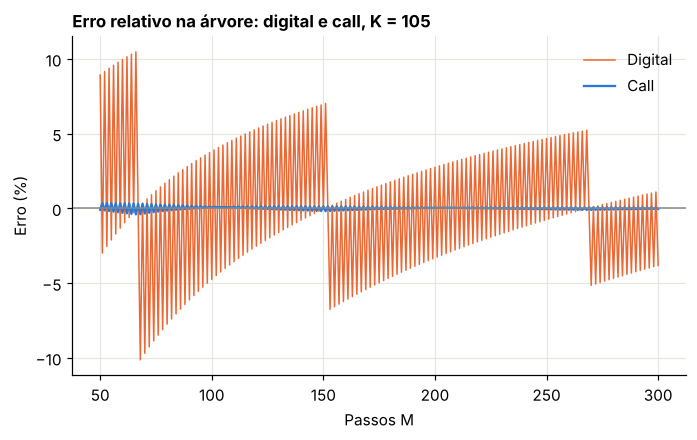

Maior erro relativo (%): digital 10,481 | call 0,395
OK — um payoff descontínuo tem erro relativo bem maior


In [9]:
def payoff_tree(pay, S0, T, r, sig, M):
    dt, u, d, q = params_crr(T, r, sig, M)
    j = np.arange(M + 1)
    return recursao(pay(S0 * u**j * d ** (M - j)), u, d, q, dt, r, M)


K_d = 105.0
ref_dig = float(np.exp(-r0 * T0) * norm.cdf(d12(S0, K_d, T0, r0, s0)[1]))
pay_d = lambda S: np.where(S > K_d, 1.0, 0.0)
ref_cal = float(bsm(S0, K_d, T0, r0, s0))
pay_c = lambda S: np.maximum(S - K_d, 0.0)

Ms2 = np.arange(50, 301)
e_d = np.array([payoff_tree(pay_d, S0, T0, r0, s0, int(M)) for M in Ms2]) - ref_dig
e_c = np.array([payoff_tree(pay_c, S0, T0, r0, s0, int(M)) for M in Ms2]) - ref_cal

fig, ax = plt.subplots()
ax.plot(Ms2, e_d / ref_dig * 100, color=LARANJA, lw=1, label="Digital")
ax.plot(Ms2, e_c / ref_cal * 100, color=AZUL, lw=1.5, label="Call")
ax.axhline(0, color=CINZA, lw=1)
ax.set_title("Erro relativo na árvore: digital e call, K = 105")
ax.set_xlabel("Passos M")
ax.set_ylabel("Erro (%)")
ax.legend()
plt.show()

print("Maior erro relativo (%): digital", f3(float(np.max(np.abs(e_d / ref_dig)) * 100)), "| call", f3(float(np.max(np.abs(e_c / ref_cal)) * 100)))
ok(np.max(np.abs(e_d / ref_dig)) > 3 * np.max(np.abs(e_c / ref_cal)), "um payoff descontínuo tem erro relativo bem maior")

---
## 7. A árvore é um método de diferenças finitas

Escreva a recursão CRR com $V_j^t$ o valor no nó de log-preço $x_j$:

$$V_j^{t} = e^{-r\Delta t}\big[q\,V_{j+1}^{t+\Delta t} + (1-q)\,V_{j-1}^{t+\Delta t}\big].$$

Vamos expandir o lado direito em Taylor, em torno de $(x, t+\Delta t)$, com passo $\Delta x = \sigma\sqrt{\Delta t}$:

$$qV_{j+1} + (1-q)V_{j-1} = V + (2q-1)\Delta x\,V_x + \tfrac12\Delta x^2\,V_{xx} + \dots$$

Usando $(2q-1)\Delta x = (r - \tfrac12\sigma^2)\Delta t$ e $\Delta x^2 = \sigma^2\Delta t$, e expandindo $e^{-r\Delta t} \approx 1 - r\Delta t$:

$$V^t = V^{t+\Delta t} + \Delta t\big[(r - \tfrac12\sigma^2)V_x + \tfrac12\sigma^2V_{xx} - rV\big] + \dots$$

Dividindo por $\Delta t$ e tomando o limite:

$$V_t + (r - \tfrac12\sigma^2)V_x + \tfrac12\sigma^2V_{xx} - rV = 0.$$

**É a EDP de Black-Scholes em log-preço**, a mesma que resolvemos no Módulo 5. A árvore é um esquema explícito de diferenças finitas, com a escolha particular $\Delta x^2 = \sigma^2\Delta t$, que fica no limite de estabilidade. Isso explica também a ordem de convergência $1/M$: é a do esquema explícito no tempo.

---
## 8. Síntese

- A árvore CRR é a do Módulo 3, com $ud = 1$ para recombinar.
- O termo $-\tfrac12\sigma^2$ surge sozinho da condição de martingale.
- A soma binomial converge para BSM, e $q'$ é o análogo discreto de $N(d_1)$.
- O erro oscila conforme a posição de $K$ nos nós; BBSR e Leisen-Reimer eliminam quase todo o erro.
- Os primeiros nós dão as gregas de graça.
- Basta um `max` para precificar americanas: call sem dividendos é igual à europeia, e a put tem fronteira de exercício.
- Valores de referência por simulação costumam ser bermudanos.
- A árvore é um esquema explícito de diferenças finitas da EDP.

## 9. Notas sobre o livro neste trecho

| Local | Comentário |
|---|---|
| Nota da Tabela 5.1 | diz "put"; a tabela é de call |
| §5.4, após a Figura 5.8 | atribui a oscilação a "parametrização diferente"; o motivo é a paridade de $M$ em relação à posição de $K$ |

## 10. Exercícios

**Exercício 1.** Para $M = 2$, com $S_0 = K = 100$, $T = 1$, $r = 5\%$, $\sigma = 20\%$, calcule à mão a call.

<details><summary>Solução</summary>

$\Delta t = 0{,}500$, $u = e^{0{,}141} = 1{,}152$, $d = 0{,}868$, $q = (1{,}025 - 0{,}868)/0{,}284 = 0{,}554$. Em $T$: $S_{uu} = 132{,}690$, payoff $32{,}690$; os demais não pagam. Valor: $e^{-0{,}05}\times 0{,}554^2\times 32{,}690 = 9{,}541$.
</details>

**Exercício 2.** Por que os nós intermediários não precisam ser guardados na versão vetorizada?

<details><summary>Solução</summary>

Cada coluna só depende da seguinte. Para opções americanas, os preços do nó são recalculados por fórmula em cada data, de forma que não há necessidade de manter a matriz inteira.
</details>

**Exercício 3.** Modifique `arvore_gregas` para índice que paga dividendo contínuo $y$. Com $y > 0$, a call americana pode ser exercida antes?

<details><summary>Solução</summary>

Troque $q$ por $(e^{(r-y)\Delta t} - d)/(u - d)$. A desigualdade $C \ge S - Ke^{-r\tau}$ vira $C \ge Se^{-y\tau} - Ke^{-r\tau}$, que pode ser menor que $S - K$: o exercício antecipado passa a ser possível.
</details>

**Exercício 4.** Calcule o número mínimo de passos para que $q \in (0, 1)$ com $r = 15\%$, $\sigma = 10\%$, $T = 2$.

<details><summary>Solução</summary>

$M > r^2T/\sigma^2 = 0{,}0225 \times 2/0{,}01 = 4{,}5$. Logo, $M \ge 5$.
</details>

**Exercício 5.** Por que uma árvore recombinante não serve diretamente para uma opção asiática? O que seria necessário?

<details><summary>Solução</summary>

O payoff depende da média do caminho, e caminhos diferentes que se reencontram num nó têm médias diferentes. Seria preciso guardar a média como variável de estado adicional, em cada nó, ou recorrer à simulação de Monte Carlo.
</details>

In [10]:
print(f"Módulo 6 concluído: {_checks['n']} verificações aprovadas.")

Módulo 6 concluído: 27 verificações aprovadas.
